1. Extração dos arquivos

Nesta etapa, o arquivo ZIP do dataset é extraído e os arquivos disponíveis são listados para identificar a base de dados que será utilizada no projeto.

In [2]:
import zipfile
import os

arquivo_zip = '/content/heart+disease.zip'
pasta_destino = '/content/heart_disease'

with zipfile.ZipFile(arquivo_zip, 'r') as zip_ref:
    zip_ref.extractall(pasta_destino)

print("Extração concluída!\n")

for raiz, pastas, arquivos in os.walk(pasta_destino):
    for arquivo in arquivos:
        print(os.path.join(raiz, arquivo))

Extração concluída!

/content/heart_disease/ask-detrano
/content/heart_disease/processed.switzerland.data
/content/heart_disease/Index
/content/heart_disease/cleveland.data
/content/heart_disease/cleve.mod
/content/heart_disease/new.data
/content/heart_disease/WARNING
/content/heart_disease/long-beach-va.data
/content/heart_disease/hungarian.data
/content/heart_disease/processed.hungarian.data
/content/heart_disease/heart-disease.names
/content/heart_disease/switzerland.data
/content/heart_disease/reprocessed.hungarian.data
/content/heart_disease/processed.va.data
/content/heart_disease/processed.cleveland.data
/content/heart_disease/bak
/content/heart_disease/costs/Index
/content/heart_disease/costs/heart-disease.cost
/content/heart_disease/costs/heart-disease.README
/content/heart_disease/costs/heart-disease.group
/content/heart_disease/costs/heart-disease.delay
/content/heart_disease/costs/heart-disease.expense


2. Carregamento dos dados

É realizada a leitura do arquivo processed.cleveland.data, utilizando o Pandas. Também são definidos os nomes das 14 colunas e carregados os 303 registros do conjunto de dados.

In [3]:
import pandas as pd
import numpy as np

caminho = '/content/heart_disease/processed.cleveland.data'

colunas = [
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal', 'num'
]

df = pd.read_csv(
    caminho,
    names=colunas,
    na_values='?',
    skipinitialspace=True
)

display(df.head())

print("Quantidade de registros:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Quantidade de registros: 303
Quantidade de colunas: 14


3. Análise exploratória dos dados

São verificadas as informações gerais da base, os tipos de dados, os valores ausentes e as estatísticas descritivas. Também é analisada a distribuição das classificações originais de doença cardíaca.

In [4]:

print("Informações do conjunto de dados:")
df.info()

print("\nQuantidade de valores ausentes por coluna:")
display(df.isnull().sum())

print("\nEstatísticas descritivas:")
display(df.describe())

print("\nDistribuição da variável alvo (num):")
display(df['num'].value_counts().sort_index())

Informações do conjunto de dados:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Quantidade de valores ausentes por coluna:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0



Estatísticas descritivas:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000



Distribuição da variável alvo (num):


,count
num,
0,164
1,55
2,36
3,35
4,13


4. Transformação e limpeza dos dados

A variável-alvo é transformada em uma classificação binária: 0 para ausência de doença e 1 para presença de doença. Também são removidos possíveis registros duplicados e as linhas são embaralhadas.

In [5]:

df_tratado = df.copy()

#0 = ausência de doença
#1 = presença de doença
df_tratado['num'] = (df_tratado['num'] > 0).astype(int)

#Removendo registros duplicados
duplicados = df_tratado.duplicated().sum()
df_tratado = df_tratado.drop_duplicates()

df_tratado = df_tratado.sample(frac=1, random_state=42).reset_index(drop=True)

print("Registros duplicados encontrados:", duplicados)
print("Quantidade de registros após tratamento:", len(df_tratado))

print("\nDistribuição da variável alvo após transformação:")
display(df_tratado['num'].value_counts())

print("\nVisualização dos dados tratados:")
display(df_tratado.head())

Registros duplicados encontrados: 0
Quantidade de registros após tratamento: 303

Distribuição da variável alvo após transformação:


,count
num,
0,164
1,139



Visualização dos dados tratados:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,53.0,1.0,3.0,130.0,246.0,1.0,2.0,173.0,0.0,0.0,1.0,3.0,3.0,0
1,54.0,1.0,4.0,110.0,206.0,0.0,2.0,108.0,1.0,0.0,2.0,1.0,3.0,1
2,56.0,1.0,4.0,125.0,249.0,1.0,2.0,144.0,1.0,1.2,2.0,1.0,3.0,1
3,58.0,1.0,4.0,100.0,234.0,0.0,0.0,156.0,0.0,0.1,1.0,1.0,7.0,1
4,51.0,0.0,4.0,130.0,305.0,0.0,0.0,142.0,1.0,1.2,2.0,0.0,7.0,1


5. Divisão dos dados

Os registros são separados em três conjuntos: 70% para treinamento, 15% para validação e 15% para teste. Essa divisão permite treinar e avaliar o modelo utilizando dados diferentes.

In [6]:
from sklearn.model_selection import train_test_split


X = df_tratado.drop('num', axis=1)
y = df_tratado['num']

#70% treinamento e 30% restante
X_treino, X_temp, y_treino, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

#15% validação e 15% teste
X_validacao, X_teste, y_validacao, y_teste = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

#para conferir
print("Quantidade de registros:")
print("Treinamento:", len(X_treino))
print("Validação:", len(X_validacao))
print("Teste:", len(X_teste))

print("\nDistribuição das classes:")
print("Treinamento:")
print(y_treino.value_counts())

print("\nValidação:")
print(y_validacao.value_counts())

print("\nTeste:")
print(y_teste.value_counts())

Quantidade de registros:
Treinamento: 212
Validação: 45
Teste: 46

Distribuição das classes:
Treinamento:
num
0    115
1     97
Name: count, dtype: int64

Validação:
num
0    24
1    21
Name: count, dtype: int64

Teste:
num
0    25
1    21
Name: count, dtype: int64


6. Configuração do pré-processamento

São configurados tratamentos específicos para variáveis numéricas e categóricas. Os valores ausentes são preenchidos, os dados numéricos são padronizados e as categorias são convertidas para um formato adequado ao modelo.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

colunas_numericas = [
    'age', 'trestbps', 'chol', 'thalach', 'oldpeak'
]

colunas_categoricas = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

pipeline_numerico = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='median')),
    ('padronizador', StandardScaler())
])

pipeline_categorico = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('codificador', OneHotEncoder(handle_unknown='ignore'))
])

preprocessador = ColumnTransformer(transformers=[
    ('numericas', pipeline_numerico, colunas_numericas),
    ('categoricas', pipeline_categorico, colunas_categoricas)
])

print("Esteira de pré-processamento configurada com sucesso!")

Esteira de pré-processamento configurada com sucesso!


7. Treinamento do modelo

É criado o modelo Random Forest, composto por várias árvores de decisão. O pré-processamento é integrado ao algoritmo em uma única esteira, que é treinada utilizando os dados de treinamento.

In [8]:
from sklearn.ensemble import RandomForestClassifier

modelo = Pipeline(steps=[
    ('preprocessamento', preprocessador),
    ('classificador', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight='balanced'
    ))
])

modelo.fit(X_treino, y_treino)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


8. Avaliação com os dados de validação

O modelo é avaliado com os dados de validação, permitindo verificar seu desempenho por meio da acurácia, precisão, recall e F1-score.

In [9]:
from sklearn.metrics import accuracy_score, classification_report

previsoes_validacao = modelo.predict(X_validacao)

acuracia_validacao = accuracy_score(
    y_validacao,
    previsoes_validacao
)

print("Acurácia na validação:", round(acuracia_validacao * 100, 2), "%")

print("\nRelatório de classificação:")
print(classification_report(
    y_validacao,
    previsoes_validacao,
    target_names=['Sem doença', 'Com doença']
))

Acurácia na validação: 86.67 %

Relatório de classificação:
              precision    recall  f1-score   support

  Sem doença       0.85      0.92      0.88        24
  Com doença       0.89      0.81      0.85        21

    accuracy                           0.87        45
   macro avg       0.87      0.86      0.86        45
weighted avg       0.87      0.87      0.87        45



9. Avaliação final com os dados de teste

O modelo é avaliado com os dados de teste, que não participaram do treinamento. São calculadas as métricas finais para verificar sua capacidade de classificação em registros desconhecidos.

In [10]:
from sklearn.metrics import accuracy_score, classification_report

previsoes_teste = modelo.predict(X_teste)

acuracia_teste = accuracy_score(
    y_teste,
    previsoes_teste
)

print("Acurácia final:", round(acuracia_teste * 100, 2), "%")

print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    previsoes_teste,
    target_names=['Sem doença', 'Com doença']
))

Acurácia final: 76.09 %

Relatório de classificação:
              precision    recall  f1-score   support

  Sem doença       0.82      0.72      0.77        25
  Com doença       0.71      0.81      0.76        21

    accuracy                           0.76        46
   macro avg       0.76      0.76      0.76        46
weighted avg       0.77      0.76      0.76        46



10. Matriz de confusão

É gerada a matriz de confusão para apresentar visualmente os acertos e erros do modelo em cada classificação, diferenciando os registros com e sem doença cardíaca.

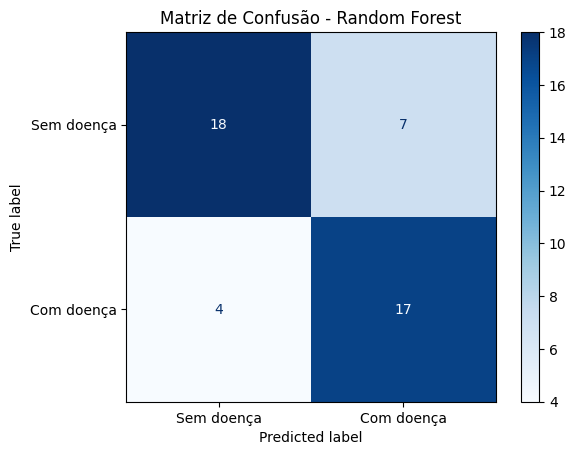

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz = confusion_matrix(y_teste, previsoes_teste)

visualizacao = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['Sem doença', 'Com doença']
)

visualizacao.plot(cmap='Blues', values_format='d')
plt.title('Matriz de Confusão - Random Forest')
plt.show()

11. Previsão individual

Por fim, um registro do conjunto de teste é utilizado para demonstrar uma previsão individual. O modelo apresenta a classificação estimada e as probabilidades correspondentes a cada classe.

In [12]:
paciente = X_teste.iloc[[0]]

previsao = modelo.predict(paciente)

probabilidades = modelo.predict_proba(paciente)

if previsao[0] == 0:
    resultado = "Ausência de doença cardíaca"
else:
    resultado = "Presença de doença cardíaca"

print("Dados do registro:")
display(paciente)

print("\nResultado da previsão:", resultado)

print("\nProbabilidades:")
print("Sem doença:", round(probabilidades[0][0] * 100, 2), "%")
print("Com doença:", round(probabilidades[0][1] * 100, 2), "%")

Dados do registro:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
72,70.0,1.0,2.0,156.0,245.0,0.0,2.0,143.0,0.0,0.0,1.0,0.0,3.0



Resultado da previsão: Ausência de doença cardíaca

Probabilidades:
Sem doença: 70.0 %
Com doença: 30.0 %
